# Várzea: o que os chamados do SP156 dizem sobre o conserto das ruas de São Paulo

**Global Solution 2026.2 · Data Science & Statistical Computing · CitizenTech**

Integrantes: ver `integrantes.txt`.

## 1. Contexto, perguntas e variáveis-alvo

A **Várzea** é um campeonato entre distritos de São Paulo: cada problema da rua resolvido e confirmado por vizinhos vale gol. Para o jogo ser justo e útil, ele precisa saber quanto tempo cada conserto costuma levar e o que seria um resultado acima do esperado para cada distrito.

**Cidadão beneficiado:** quem mora ou anda em ruas com buracos, entulho, mato e bueiros entupidos e não sabe quando o pedido será atendido.

**Perguntas:**

1. **Quantos dias** um chamado de rua tende a levar até ser finalizado?
2. **Qual a chance** de ele ser finalizado em até 30 dias?
3. **Que ações** essas previsões justificam, e quais distritos estão acima ou abaixo do esperado?

**Variáveis-alvo:**

| Modelo | Alvo | Tipo | Definição |
|---|---|---|---|
| Regressão linear | `dias` | Numérica | Dias entre abertura e finalização, em escala logarítmica no treino |
| Regressão logística | `resolvido_30d` | Binária | 1 se foi finalizado, sem cancelamento, em até 30 dias |

**Variáveis explicativas:** apenas o que já se sabe quando o chamado é aberto: `servico`, `distrito`, `canal` e `dia_semana`.

**Fonte dos dados:** [Portal de Dados Abertos da Prefeitura de São Paulo, conjunto "Dados do SP156"](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156), arquivo `arquivo-final-4-trim-25.csv` (4º trimestre de 2025). O script `preparar_dados.py` gera a base usada aqui e descarta logradouro, número, CEP, latitude e longitude.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, LARANJA, CINZA = '#1f6f8b', '#d9822b', '#9aa5ab'

## 2. Preparação dos dados

A base traz 20 serviços em que o morador consegue ver o resultado na rua. Ficam de fora fiscalização (como PSIU e ambulantes) e pedidos de avaliação (como poda de árvore), porque neles o fechamento não significa conserto visível. Esse recorte foi definido pelo tipo de serviço, sem olhar o resultado dos chamados.

In [2]:
base = pd.read_csv('sp156_ruas_4t2025.csv')
base['data_abertura'] = pd.to_datetime(base['data_abertura'], format='%d/%m/%Y')
base['data_finalizacao'] = pd.to_datetime(base['data_finalizacao'], format='%d/%m/%Y')

print('Linhas e colunas:', base.shape)
print('Abertura de', base.data_abertura.min().date(), 'a', base.data_abertura.max().date())
print('Última finalização registrada:', base.data_finalizacao.max().date())
print('Distritos:', base.distrito.nunique(), '| Serviços:', base.servico.nunique())
print('\nValores ausentes por coluna (%):')
print((base.isna().mean() * 100).round(1).to_string())
print('\nStatus:')
print(base.status.value_counts().to_string())

Linhas e colunas: (104604, 7)
Abertura de 2025-10-01 a 2025-12-31
Última finalização registrada: 2026-08-07
Distritos: 96 | Serviços: 20

Valores ausentes por coluna (%):
data_abertura       0.0
data_finalizacao    5.2
canal               0.0
categoria           0.0
servico             0.0
status              0.0
distrito            0.0

Status:
status
Finalizada    98707
Aberto         5394
Cancelada       503


In [3]:
base['dias'] = (base.data_finalizacao - base.data_abertura).dt.days
base['dia_semana'] = base.data_abertura.dt.day_name()
base['resolvido_30d'] = (base.dias.le(30) & base.status.ne('Cancelada')).astype(int)

print('Dias negativos:', (base.dias < 0).sum())
print('Abertos ou em andamento sem data de finalização:', base.dias.isna().sum())
print('Menor acompanhamento possível (dias entre a última abertura e a última finalização):',
      (base.data_finalizacao.max() - base.data_abertura.max()).days)
print('Finalizados em até 30 dias: %.1f%%' % (base.resolvido_30d.mean() * 100))
base[['categoria', 'servico', 'distrito', 'canal', 'dia_semana', 'status', 'dias', 'resolvido_30d']].head()

Dias negativos: 0
Abertos ou em andamento sem data de finalização: 5402
Menor acompanhamento possível (dias entre a última abertura e a última finalização): 219
Finalizados em até 30 dias: 88.1%


,categoria,servico,distrito,canal,dia_semana,status,dias,resolvido_30d
0,Drenagem,Drenagem de água da chuva - Bueiros e bocas de lobo,JOSE BONIFACIO,MOBILE,Tuesday,Cancelada,47.0,0
1,Limpeza e mato,Fazer reclamação de falta de varrição,BELEM,MOBILE,Saturday,Finalizada,1.0,1
2,Pavimento,"Guias, sarjetas e sarjetões - solicitar manutenção",FREGUESIA DO O,MOBILE,Monday,Finalizada,51.0,0
3,Entulho e lixo,Entulho e grandes objetos em via pública - solicitar remoção,TREMEMBE,PORTAL,Saturday,Finalizada,2.0,1
4,Entulho e lixo,Entulho e grandes objetos em via pública - solicitar remoção,MORUMBI,MOBILE,Saturday,Finalizada,0.0,1


**Valores ausentes:** `data_finalizacao` só falta em chamados ainda sem finalização. Eles não são erro: entram na logística como "não resolvido em 30 dias", pois todos tiveram mais de 30 dias de acompanhamento. Ficam de fora da linear, que precisa de um número de dias.

### Exploração

,chamados,mediana_dias,p90_dias,resolvido_30d
categoria,,,,
Praças,327,21.0,119.0,52.6
Calçada,1597,11.0,105.0,60.2
Pavimento,30366,7.0,40.0,77.3
Drenagem,10625,4.0,53.0,78.0
Limpeza e mato,19936,1.0,24.0,91.7
Entulho e lixo,41753,1.0,4.0,98.1


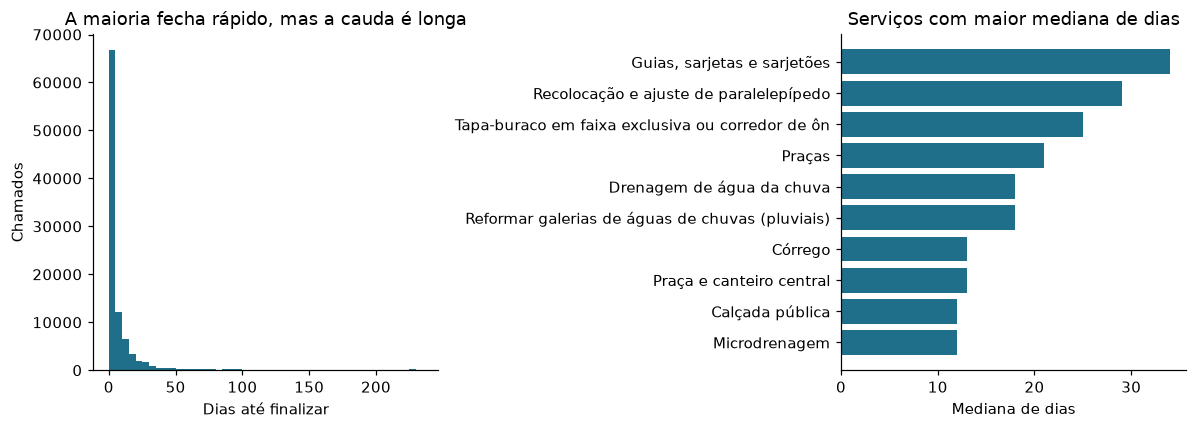

In [4]:
resumo = (base.groupby('categoria')
          .agg(chamados=('dias', 'size'), mediana_dias=('dias', 'median'),
               p90_dias=('dias', lambda s: s.quantile(.9)), resolvido_30d=('resolvido_30d', 'mean'))
          .sort_values('resolvido_30d'))
resumo['resolvido_30d'] = (resumo['resolvido_30d'] * 100).round(1)
display(resumo)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(base.dias.dropna(), bins=range(0, 240, 5), color=AZUL)
ax[0].set(title='A maioria fecha rápido, mas a cauda é longa', xlabel='Dias até finalizar', ylabel='Chamados')
por_servico = base.groupby('servico').dias.median().sort_values().tail(10)
ax[1].barh([s.split(' - ')[0][:48] for s in por_servico.index], por_servico.values, color=AZUL)
ax[1].set(title='Serviços com maior mediana de dias', xlabel='Mediana de dias')
plt.tight_layout(); plt.show()

**O que a exploração mostra:** 88,1% dos chamados são finalizados em até 30 dias, mas a média esconde dois mundos. Entulho e lixo resolve 98,1% nesse prazo, com mediana de 1 dia. Calçadas ficam em 60,2% e praças em 52,6%. Como `dias` tem cauda longa, a linear aprende o logaritmo de `dias`.

### Separação entre treino e teste, sem vazamento

A separação é **temporal**, porque o objetivo é prever chamados futuros:

| Conjunto | Abertura | Uso |
|---|---|---|
| Treino | Outubro | Ajustar os modelos |
| Fora | Novembro | Não entra em nenhum dos dois conjuntos |
| Teste | Dezembro | Avaliar só no final |

**Por que novembro fica de fora?** Em 1º de dezembro, ainda não saberíamos quais chamados de novembro seriam resolvidos em 30 dias. Usá-los no treino traria informação do futuro.

**Outros cuidados contra vazamento:**

- `status` e `data_finalizacao` não entram como variáveis, pois só são conhecidos depois.
- O codificador é ajustado só no treino, dentro de um `Pipeline`, e categorias novas no teste são tratadas como desconhecidas.
- Na linear, os dois períodos usam a mesma janela de 210 dias, porque chamados de dezembro tiveram menos tempo para fechar. Sem isso, os de outubro teriam prazos longos que os de dezembro ainda não poderiam ter.

**Limite que permanece:** o treino da linear usa finalizações ocorridas depois de 1º de dezembro. Para uso real, o modelo precisaria ser treinado com chamados mais antigos.

In [5]:
X_COLS = ['servico', 'distrito', 'canal', 'dia_semana']
treino = base[base.data_abertura < '2025-11-01']
teste = base[base.data_abertura >= '2025-12-01']
print('Treino (outubro):', len(treino), '| Teste (dezembro):', len(teste), '| Fora (novembro):', len(base) - len(treino) - len(teste))

JANELA = 210
def so_finalizados(df):
    return df[df.status.ne('Cancelada') & df.dias.between(0, JANELA)]

treino_lin, teste_lin = so_finalizados(treino), so_finalizados(teste)
print('Linear, treino:', len(treino_lin), '| teste:', len(teste_lin))

def novo_codificador():
    return ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore', drop='first', min_frequency=20), X_COLS)])

Treino (outubro): 35330 | Teste (dezembro): 35192 | Fora (novembro): 34082
Linear, treino: 33135 | teste: 32823


## 3. Regressão linear: quantos dias até finalizar?

`dias` tem cauda longa, então o modelo aprende `log(1 + dias)`, e as previsões voltam para dias antes de calcular as métricas. Comparamos com um chute simples: a mediana de dias do treino.

In [6]:
modelo_linear = make_pipeline(novo_codificador(), LinearRegression())
modelo_linear.fit(treino_lin[X_COLS], np.log1p(treino_lin.dias))

log_previsto = modelo_linear.predict(teste_lin[X_COLS])
previsto = np.expm1(log_previsto).clip(0)
real = teste_lin.dias
chute = np.full(len(real), treino_lin.dias.median())

def metricas(y, p):
    return {'MAE (dias)': mean_absolute_error(y, p), 'RMSE (dias)': mean_squared_error(y, p) ** .5, 'R²': r2_score(y, p)}

resultado_linear = pd.DataFrame({'Modelo': metricas(real, previsto), 'Chute (mediana)': metricas(real, chute)}).round(3)
display(resultado_linear)
print('R² na escala logarítmica: %.3f' % r2_score(np.log1p(real), log_previsto))
print('Mediana do erro absoluto: %.1f dias' % np.median(np.abs(real - previsto)))

,Modelo,Chute (mediana)
MAE (dias),6.605,7.608
RMSE (dias),19.602,22.481
R²,0.177,-0.083


R² na escala logarítmica: 0.417
Mediana do erro absoluto: 1.5 dias


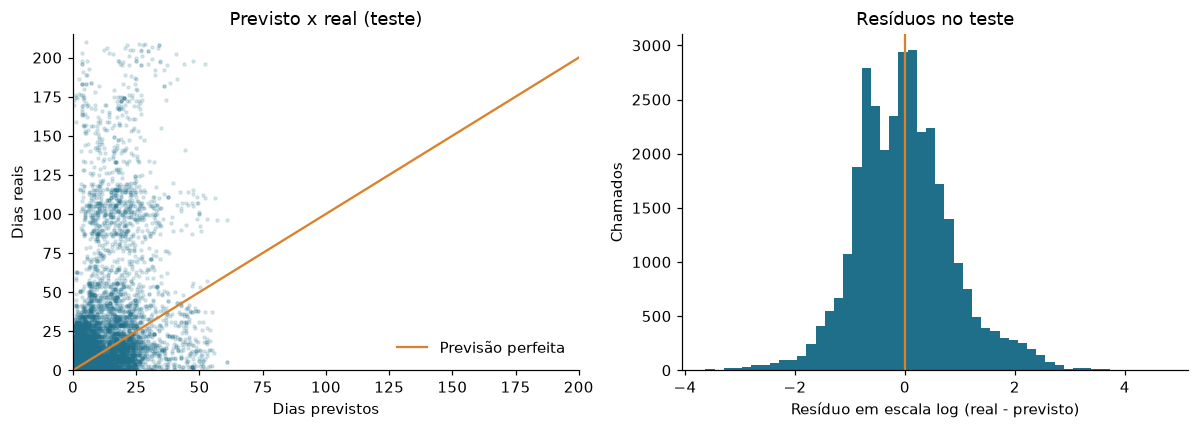

Distrito e canal de referência: {'distrito': 'LAPA', 'canal': 'MOBILE', 'dia_semana': 'Monday'}


,servico,dias_previstos
12,Recolocação e ajuste de paralelepípedo,32.6
8,"Guias, sarjetas e sarjetões - solicitar manutenção",30.3
17,Tapa-buraco em faixa exclusiva ou corredor de ônibus,26.9
11,"Praças - Solicitar manutenção de equipamentos (mesas, bancos, brin...",25.1
13,Reformar galerias de águas de chuvas (pluviais),23.1
4,Drenagem de água da chuva - Bueiros e bocas de lobo,22.0
2,Córrego - solicitar limpeza,17.5
0,Calçada pública - solicitar manutenção,14.6
10,Praça e canteiro central - solicitar roçada,10.7
18,Vielas e escadarias - solicitar manutenção,9.1


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(previsto, real, s=4, alpha=.15, color=AZUL)
ax[0].plot([0, 200], [0, 200], color=LARANJA, label='Previsão perfeita')
ax[0].set(xlim=(0, 200), ylim=(0, 215), xlabel='Dias previstos', ylabel='Dias reais', title='Previsto x real (teste)')
ax[0].legend(frameon=False)
residuo = np.log1p(real) - log_previsto
ax[1].hist(residuo, bins=50, color=AZUL)
ax[1].axvline(0, color=LARANJA)
ax[1].set(xlabel='Resíduo em escala log (real - previsto)', ylabel='Chamados', title='Resíduos no teste')
plt.tight_layout(); plt.show()

# Efeito de cada serviço: previsão para um chamado igual, mudando só o serviço
referencia = {'distrito': treino_lin.distrito.mode()[0], 'canal': treino_lin.canal.mode()[0], 'dia_semana': 'Monday'}
servicos = sorted(treino_lin.servico.value_counts().loc[lambda s: s >= 50].index)
efeito = pd.DataFrame([{**referencia, 'servico': s} for s in servicos])
efeito['dias_previstos'] = np.expm1(modelo_linear.predict(efeito[X_COLS])).round(1)
print('Distrito e canal de referência:', referencia)
display(efeito[['servico', 'dias_previstos']].sort_values('dias_previstos', ascending=False))

### Interpretação da regressão linear

- **MAE de 6,6 dias:** em média, a previsão erra 6,6 dias, contra 7,6 do chute pela mediana. O ganho é real, mas modesto.
- **RMSE de 19,6 dias:** bem maior que o MAE, porque poucos chamados muito demorados geram erros grandes.
- **R² de 0,18 em dias e 0,42 em escala logarítmica:** serviço, distrito, canal e dia explicam parte da variação, mas não a maior parte. Faltam informações como equipe disponível, contrato e gravidade.
- **Mediana do erro de 1,5 dia:** o modelo acerta bem o chamado típico e falha nos casos longos. O gráfico mostra isso: as previsões quase não passam de 60 dias, mesmo com casos reais de até 210. Voltar da escala logarítmica também aproxima a mediana, e não a média.
- **O serviço pesa muito:** para um chamado igual na Lapa, feito pelo celular em uma segunda-feira, a previsão vai de 1,7 dia para entulho a 30,3 dias para guias e sarjetas, e 32,6 para paralelepípedo.

**Conclusão:** o modelo serve para dar uma ordem de grandeza ao morador, e não um prazo prometido. Mostrar "cerca de 5 dias" é aceitável, mas o app deve dizer que é uma estimativa. **Atenção:** o valor de 0,1 dia para descarte irregular é um fechamento quase imediato, o que pode indicar encaminhamento administrativo, e não remoção do entulho.

## 4. Regressão logística: qual a chance de finalizar em até 30 dias?

Aqui entram todos os chamados, inclusive os abertos e cancelados, que contam como `resolvido_30d = 0`. Isso evita olhar só para quem foi atendido.

,Modelo,Chute (sempre sim)
Precisão,0.919,0.881
Recall,0.971,1.000
F1,0.944,0.937
Acurácia,0.899,0.881


AUC: 0.841


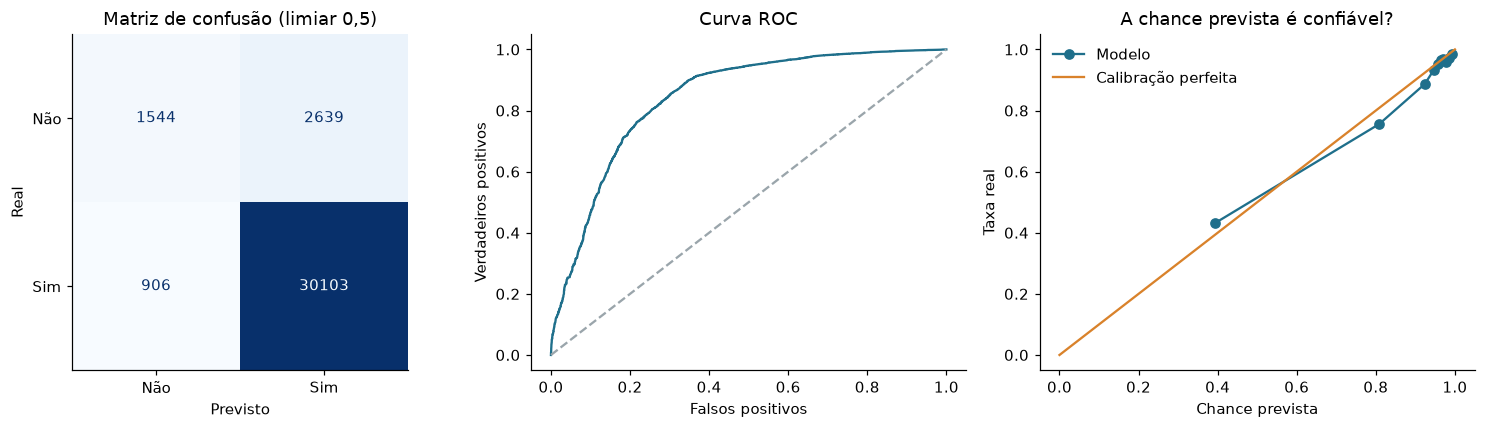

                 chance prevista  taxa real
faixa                                      
(0.0799, 0.625]            0.393      0.431
(0.625, 0.904]             0.809      0.756
(0.904, 0.939]             0.924      0.887
(0.939, 0.953]             0.946      0.932
(0.953, 0.961]             0.957      0.953
(0.961, 0.968]             0.965      0.965
(0.968, 0.974]             0.971      0.968
(0.974, 0.981]             0.978      0.961
(0.981, 0.989]             0.985      0.973
(0.989, 0.999]             0.993      0.986


In [8]:
modelo_logistico = make_pipeline(novo_codificador(), LogisticRegression(max_iter=2000))
modelo_logistico.fit(treino[X_COLS], treino.resolvido_30d)

y_teste = teste.resolvido_30d
prob = modelo_logistico.predict_proba(teste[X_COLS])[:, 1]
y_prev = (prob >= .5).astype(int)

def metricas_classe(y, p):
    return {'Precisão': precision_score(y, p, zero_division=0), 'Recall': recall_score(y, p), 'F1': f1_score(y, p), 'Acurácia': (y == p).mean()}

sempre_sim = np.ones(len(y_teste), dtype=int)
resultado_log = pd.DataFrame({'Modelo': metricas_classe(y_teste, y_prev), 'Chute (sempre sim)': metricas_classe(y_teste, sempre_sim)}).round(3)
display(resultado_log)
print('AUC: %.3f' % roc_auc_score(y_teste, prob))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ConfusionMatrixDisplay(confusion_matrix(y_teste, y_prev), display_labels=['Não', 'Sim']).plot(ax=ax[0], colorbar=False, cmap='Blues', values_format='d')
ax[0].set(title='Matriz de confusão (limiar 0,5)', xlabel='Previsto', ylabel='Real')
fpr, tpr, _ = roc_curve(y_teste, prob)
ax[1].plot(fpr, tpr, color=AZUL); ax[1].plot([0, 1], [0, 1], color=CINZA, ls='--')
ax[1].set(title='Curva ROC', xlabel='Falsos positivos', ylabel='Verdadeiros positivos')
faixas = pd.DataFrame({'p': prob, 'y': y_teste.values}).assign(faixa=lambda d: pd.qcut(d.p, 10, duplicates='drop')).groupby('faixa', observed=True).mean()
ax[2].plot(faixas.p, faixas.y, 'o-', color=AZUL, label='Modelo')
ax[2].plot([0, 1], [0, 1], color=LARANJA, label='Calibração perfeita')
ax[2].set(title='A chance prevista é confiável?', xlabel='Chance prevista', ylabel='Taxa real'); ax[2].legend(frameon=False)
plt.tight_layout(); plt.show()
print(faixas[['p', 'y']].round(3).rename(columns={'p': 'chance prevista', 'y': 'taxa real'}).to_string())

### Alerta de risco

O uso mais útil é encontrar os chamados com **risco de atrasar**. O limiar não pode ser escolhido olhando o teste, então é definido dentro de outubro: treinamos na primeira quinzena e escolhemos, na segunda, o limiar que dá o melhor F1 para a classe "atrasa". Depois, avaliamos em dezembro.

In [9]:
ajuste = treino[treino.data_abertura < '2025-10-16']
validacao = treino[treino.data_abertura >= '2025-10-16']
modelo_ajuste = make_pipeline(novo_codificador(), LogisticRegression(max_iter=2000)).fit(ajuste[X_COLS], ajuste.resolvido_30d)
prob_val = modelo_ajuste.predict_proba(validacao[X_COLS])[:, 1]

limiares = np.arange(.3, .96, .01)
f1_atraso = [f1_score(1 - validacao.resolvido_30d, (prob_val < l).astype(int)) for l in limiares]
limiar = limiares[int(np.argmax(f1_atraso))]

atraso_real = 1 - y_teste
alerta = (prob < limiar).astype(int)
print('Limiar escolhido na validação: %.2f' % limiar)
print('Chamados em alerta no teste: %d de %d (%.1f%%)' % (alerta.sum(), len(alerta), alerta.mean() * 100))
print('Taxa real de atraso em dezembro: %.1f%%' % (atraso_real.mean() * 100))
print('Precisão do alerta: %.3f | Recall do alerta: %.3f | F1: %.3f' % (precision_score(atraso_real, alerta), recall_score(atraso_real, alerta), f1_score(atraso_real, alerta)))
display(pd.DataFrame(confusion_matrix(atraso_real, alerta), index=['Real: no prazo', 'Real: atrasou'], columns=['Sem alerta', 'Com alerta']))

Limiar escolhido na validação: 0.82
Chamados em alerta no teste: 5091 de 35192 (14.5%)
Taxa real de atraso em dezembro: 11.9%
Precisão do alerta: 0.504 | Recall do alerta: 0.614 | F1: 0.554


,Sem alerta,Com alerta
Real: no prazo,28486,2523
Real: atrasou,1615,2568


### Interpretação da regressão logística

- **Matriz e métricas:** com limiar 0,5, a precisão é 0,92, o recall 0,97 e o F1 0,94. Quando o modelo diz "vai resolver", acerta 92% das vezes.
- **Cuidado com o desbalanceamento:** chutar sempre "sim" já dá acurácia de 0,88 e F1 de 0,94. Por isso, a acurácia de 0,90 e o F1 impressionam menos do que parecem.
- **AUC de 0,84:** é a medida mais informativa aqui. Em 84% dos pares formados por um chamado resolvido e um atrasado, o modelo dá chance maior ao resolvido.
- **Calibração:** nas faixas altas, a chance prevista fica perto da real. Na faixa de 0,63 a 0,90, o modelo foi otimista: previu 81%, e o real foi 76%.
- **Alerta de risco:** com limiar 0,82, o alerta marcou 14,5% dos chamados de dezembro e pegou 61,4% dos atrasos. Dos alertados, 50,4% atrasaram, mais de 4 vezes a taxa geral de 11,9%. Em contrapartida, 2.523 alertas foram falsos e 1.615 atrasos escaparam.
- **O alerta depende muito do serviço:** todos os 1.850 chamados de guias e sarjetas foram alertados, contra só 13 dos 7.031 de tapa-buraco. Por isso, ele acha serviços problemáticos melhor do que chamados problemáticos dentro de um mesmo serviço.

**Conclusão:** esta previsão é mais útil que a linear, e serve melhor para ordenar prioridades do que para julgar um chamado isolado.

## 5. Do modelo às ações

### Quem joga acima do esperado?

Comparar distritos pela taxa bruta seria injusto, pois cada um tem uma mistura diferente de pedidos. O modelo calcula quantos chamados **seriam** finalizados em até 30 dias dada essa mistura. O saldo é a diferença entre o real e o esperado, descontada a mudança que afetou a cidade inteira. Isso cria um placar mais justo para a Várzea.

Cidade em dezembro: real 88.1% | esperado pelo modelo de outubro 89.2%
Distritos com pelo menos 100 chamados em dezembro: 91
Saldo maior que a margem de erro: 29


,chamados,real,esperado,saldo_pontos,margem_95
distrito,,,,,
VILA ANDRADE,295,84.7,76.0,9.8,4.1
ITAIM PAULISTA,535,89.5,83.4,7.2,2.6
BARRA FUNDA,144,93.1,87.5,6.7,4.2
MOEMA,142,85.2,80.5,5.8,5.8
CAMPO LIMPO,673,91.1,86.4,5.7,2.2


,chamados,real,esperado,saldo_pontos,margem_95
distrito,,,,,
BELA VISTA,143,67.8,80.8,-11.9,7.7
CONSOLACAO,132,63.6,75.6,-10.8,8.2
SANTO AMARO,467,85.7,94.6,-7.9,3.2
ANHANGUERA,193,89.6,98.0,-7.3,4.3
SAO RAFAEL,416,86.1,93.8,-6.7,3.3


,chamados,real,esperado,saldo_pontos,margem_95
distrito,,,,,
MOOCA,224,89.3,95.5,-5.2,4.1
TATUAPE,204,90.2,91.1,0.2,4.1
VILA PRUDENTE,451,97.1,97.6,0.6,1.5
PINHEIROS,183,85.8,87.2,-0.3,5.1
PERUS,273,94.9,97.7,-1.8,2.6
CIDADE TIRADENTES,309,90.0,96.5,-5.4,3.3


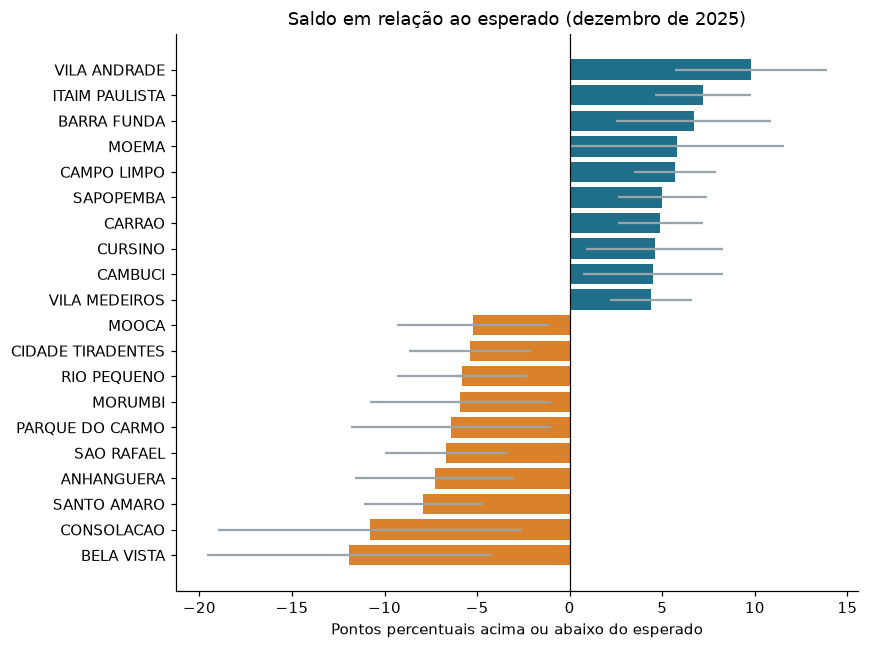

In [10]:
placar = teste.assign(esperado=prob).groupby('distrito').agg(chamados=('resolvido_30d', 'size'), real=('resolvido_30d', 'mean'), esperado=('esperado', 'mean'))
placar = placar[placar.chamados >= 100]
diferenca_cidade = y_teste.mean() - prob.mean()
print('Cidade em dezembro: real %.1f%% | esperado pelo modelo de outubro %.1f%%' % (y_teste.mean() * 100, prob.mean() * 100))
# Tira a mudança que atingiu a cidade inteira, para o saldo comparar os distritos entre si.
placar['saldo_pontos'] = (placar.real - placar.esperado - diferenca_cidade) * 100
placar['margem_95'] = 1.96 * np.sqrt(placar.real * (1 - placar.real) / placar.chamados) * 100
placar[['real', 'esperado']] = (placar[['real', 'esperado']] * 100).round(1)
placar = placar.round(1).sort_values('saldo_pontos')
print('Distritos com pelo menos 100 chamados em dezembro:', len(placar))
print('Saldo maior que a margem de erro:', (placar.saldo_pontos.abs() > placar.margem_95).sum())
display(placar.tail(5)[::-1]); display(placar.head(5))

classico = placar.reindex(['MOOCA', 'TATUAPE', 'VILA PRUDENTE', 'PINHEIROS', 'PERUS', 'CIDADE TIRADENTES'])
display(classico)

ordem = pd.concat([placar.head(10), placar.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ordem.index, ordem.saldo_pontos, xerr=ordem.margem_95, color=[LARANJA if v < 0 else AZUL for v in ordem.saldo_pontos], ecolor=CINZA)
ax.axvline(0, color='black', lw=.8)
ax.set(title='Saldo em relação ao esperado (dezembro de 2025)', xlabel='Pontos percentuais acima ou abaixo do esperado')
plt.tight_layout(); plt.show()

### Onde estão os atrasos?

In [11]:
fila = teste.assign(alerta=alerta, atrasou=atraso_real).groupby('servico').agg(chamados=('alerta', 'size'), atrasos=('atrasou', 'sum'), taxa_atraso=('atrasou', 'mean'), em_alerta=('alerta', 'sum'))
fila['parcela_dos_atrasos'] = fila.atrasos / fila.atrasos.sum() * 100
fila['taxa_atraso'] = (fila.taxa_atraso * 100).round(1)
fila = fila.sort_values('atrasos', ascending=False).round(1)
fila['parcela_acumulada'] = fila.parcela_dos_atrasos.cumsum().round(1)
display(fila.head(8))

# Cenário ilustrativo, não é previsão: e se metade dos atrasos corretamente alertados fosse evitada?
acertos = int(((alerta == 1) & (atraso_real == 1)).sum())
taxa_atual = y_teste.mean() * 100
taxa_cenario = (y_teste.sum() + acertos * .5) / len(y_teste) * 100
print('Atrasos identificados pelo alerta em dezembro:', acertos)
print('Taxa atual em 30 dias: %.1f%% | Cenário com metade evitada: %.1f%%' % (taxa_atual, taxa_cenario))

,chamados,atrasos,taxa_atraso,em_alerta,parcela_dos_atrasos,parcela_acumulada
servico,,,,,,
"Guias, sarjetas e sarjetões - solicitar manutenção",1850,1185,64.1,1850,28.3,28.3
Tapa-buraco,7031,1038,14.8,13,24.8,53.1
Praça e canteiro central - solicitar roçada,1546,529,34.2,949,12.6,65.7
Reformar galerias de águas de chuvas (pluviais),805,387,48.1,765,9.3,75.0
Entulho e grandes objetos em via pública - solicitar remoção,13032,197,1.5,0,4.7,79.7
Calçada pública - solicitar manutenção,380,148,38.9,345,3.5,83.2
Córrego - solicitar limpeza,372,145,39.0,352,3.5,86.7
"Solicitar limpeza de bueiros, boca de lobo e poços de visita",2065,145,7.0,79,3.5,90.2


Atrasos identificados pelo alerta em dezembro: 2568
Taxa atual em 30 dias: 88.1% | Cenário com metade evitada: 91.8%


## 6. Recomendações de ações

Salvo indicação, os resultados são de dezembro de 2025, conjunto que os modelos não viram no treino.

| # | Ação | Em que previsão se baseia | Quem age | Como medir |
|---|---|---|---|---|
| 1 | **Mutirão focado em guias e sarjetas, depois tapa-buraco** | Guias e sarjetas atrasam em 64,1% dos casos e somam 28,3% dos atrasos. Com tapa-buraco, são 53,1%. Quatro serviços chegam a 75,0% | Subprefeituras | Taxa de atraso desses serviços, mês a mês |
| 2 | **Alerta de risco na abertura do chamado** | O alerta pega 61,4% dos atrasos marcando só 14,5% dos chamados | Várzea avisa a subprefeitura e o morador | Taxa em 30 dias dos alertados, comparada a um grupo sem alerta |
| 3 | **Gol difícil vale mais** | No trimestre, entulho é resolvido em 98,1% dos casos em 30 dias, e calçadas, em 60,2%. Valores iguais premiariam só o fácil | Regras da Várzea | Parcela de gols em serviços de baixa chance |
| 4 | **Placar por saldo, e não por taxa bruta** | O saldo considera a mistura de pedidos: Tatuapé e Mooca têm taxa bruta parecida (90,2% e 89,3%), mas saldos de +0,2 e -5,2 pontos | Regras da Várzea | Estabilidade do placar ao longo dos meses |
| 5 | **Investigar antes de cobrar** | Bela Vista (-11,9) e Consolação (-10,8) ficam abaixo do esperado, e Vila Andrade (+9,8) fica acima. Vale entender o que muda entre eles | Subprefeituras e torcidas | Saldo nos meses seguintes |
| 6 | **VAR por amostra nos fechamentos muito rápidos** | O descarte irregular tem previsão de 0,1 dia, e o dado só diz que o chamado fechou, não que o entulho saiu | Vizinhos, pelo VAR | % de fechamentos confirmados na rua |

### Impacto possível

**Cenário ilustrativo, e não previsão:** em dezembro, o alerta identificou 2.568 atrasos. Se metade deles fosse evitada, a taxa em 30 dias subiria de 88,1% para 91,8%. Isso supõe que a Prefeitura tenha capacidade para atender esses chamados, o que os dados não mostram. O benefício iria para quem vive com os serviços mais lentos, como quem depende de calçadas, sarjetas e galerias.

## 7. Limitações

- **Finalizado não prova conserto:** o SP156 registra o fechamento do chamado, não o resultado na rua. Esta é a principal limitação, e o VAR da Várzea existe para reduzi-la.
- **Um único trimestre:** sem sazonalidade ou tendência. Dezembro tem chuva e fim de ano, e a cidade ficou 1,1 ponto abaixo do esperado pelo modelo de outubro.
- **Quem reclama:** os dados só contêm problemas que alguém relatou. Volume também reflete acesso e hábito, e por isso não medem onde há mais problemas.
- **Sem dados das pessoas:** o SP156 não informa renda, idade ou deficiência, então não dá para concluir nada sobre grupos sociais.
- **Associação, não causa:** os modelos não mostram que um canal ou distrito causa a demora. Alertar também pode mudar o comportamento que o modelo aprendeu.
- **Linear só com finalizados:** chamados sem data ficam de fora e a janela vai até 210 dias, então os casos mais demorados estão sub-representados.
- **Saldos com incerteza:** 29 dos 91 distritos têm saldo maior que a margem de 95%, mas ela não considera o erro do modelo e, entre 91 comparações, algumas passam por acaso. É preciso repetir por vários meses antes de cobrar alguém.
- **Recorte de serviços:** a escolha dos 20 serviços é um julgamento da equipe. Iluminação pública não aparece neste arquivo, e árvores e calçadas particulares ficaram de fora.
- **Dados pessoais:** logradouro, número, CEP, latitude e longitude foram removidos antes da análise.